# 05 – Pricing from the SVI surface and validation

This notebook turns the SVI parameters into a pricer that works for any strike and any maturity
between the first and the last calibrated expiry. Then it measures how well the surface reproduces
the market quotes, in price and in volatility.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from functions import black_price, svi

SNAPSHOT = "SPX_2026-10-26_1030"      # the market snapshot used in the whole project
DATA_DIR = "data"                     # folder with all input and output files

df_svi = pd.read_csv(os.path.join(DATA_DIR, SNAPSHOT + "_svi.csv"))
df_iv = pd.read_csv(os.path.join(DATA_DIR, SNAPSHOT + "_iv.csv"))
print(df_svi.shape, df_iv.shape)

(47, 12) (8997, 30)


## 1. Inputs

We build two tables:

- `surface`: one row per calibrated expiry, with the SVI parameters, the forward $F$, the rate $r$
  and the spot;
- `quotes`: one row per market quote, with the SVI parameters of its expiry, used for the validation.

Expiries that were not calibrated (rejected by the quality check in notebook 04) are dropped by the
`inner` merge.

In [2]:
exp_info = df_iv.groupby("expiry")[["F", "r", "spot"]].first().reset_index()
surface = pd.merge(df_svi, exp_info, on="expiry", how="inner")
surface = surface.sort_values("T").reset_index(drop=True)

param_cols = ["a", "b", "rho", "m", "sig"]
quotes = pd.merge(df_iv, df_svi[["expiry"] + param_cols], on="expiry", how="inner")
print(surface.shape, quotes.shape)

(47, 15) (8912, 35)


## 2. Total variance for any maturity

For a maturity $T$ between two calibrated expiries $T_1 \le T \le T_2$, we interpolate total variance
linearly in $T$ at fixed log-moneyness $k$:

$$w(k, T) = w(k, T_1) + \frac{T - T_1}{T_2 - T_1}\,\big[w(k, T_2) - w(k, T_1)\big].$$

If the two slices do not cross, the interpolated value lies between them, so this interpolation does
not create calendar arbitrage. The forward is interpolated linearly in $\ln F$ and the rate linearly
in $T$.

The surface is not extrapolated in time: for a maturity before the first or after the last
calibrated expiry, the function stops with an error instead of returning a wrong number.

In [3]:
T_list = surface["T"].values

def total_variance(k, T):
    if T < T_list[0] or T > T_list[-1]:
        raise ValueError(f"T = {T} is outside the calibrated expiries ({T_list[0]:.3f} to {T_list[-1]:.3f})")
    i = np.searchsorted(T_list, T) - 1          # T_list[i] <= T <= T_list[i + 1]
    i = min(max(i, 0), len(T_list) - 2)         # stay inside the table at the two ends
    T1, T2 = T_list[i], T_list[i + 1]
    w1 = svi(k, *surface.loc[i, param_cols])
    w2 = svi(k, *surface.loc[i + 1, param_cols])
    return w1 + (T - T1) / (T2 - T1) * (w2 - w1)

def forward(T):
    return np.exp(np.interp(T, T_list, np.log(surface["F"].values)))

def rate(T):
    return np.interp(T, T_list, surface["r"].values)

**Check.** At a calibrated maturity the interpolation must return the SVI slice itself; between two
maturities the values must lie between the two slices.

In [4]:
for T in [T_list[10], 0.5, 1.0]:
    for k in [0, -0.1]:
        w = total_variance(k, T)
        print(f"T = {T:.4f}  k = {k:5}  w = {w:.5f}  vol = {np.sqrt(w / T):.4f}")
    print(f"   F = {forward(T):.2f}  r = {rate(T):.5f}")

T = 0.0583  k =     0  w = 0.00114  vol = 0.1399
T = 0.0583  k =  -0.1  w = 0.00400  vol = 0.2619
   F = 7686.12  r = 0.03989
T = 0.5000  k =     0  w = 0.01223  vol = 0.1564
T = 0.5000  k =  -0.1  w = 0.02017  vol = 0.2009
   F = 7819.27  r = 0.04224
T = 1.0000  k =     0  w = 0.02790  vol = 0.1670
T = 1.0000  k =  -0.1  w = 0.03930  vol = 0.1982
   F = 7986.32  r = 0.04371


## 3. The pricer

For a strike $K$ and a maturity $T$, the pricer:

1. takes the forward $F(T)$ and computes $k = \ln(K / F)$;
2. reads the total variance $w(k, T)$ from the surface and the volatility $\sigma = \sqrt{w/T}$;
3. prices the option with the Black formula.

As an example we price the legs of typical equity hedges with a maturity of one year: a put at 90%
and at 70% of the current index level (the spot), and a call at 110%. Strikes are set in percent
of the spot because a hedge protects the value of the portfolio today.

In [5]:
def price(K, T, option_type):
    F = forward(T)
    k = np.log(K / F)
    w = total_variance(k, T)
    sigma = np.sqrt(w / T)
    return black_price(F, K, T, rate(T), sigma, option_type), sigma

S = surface["spot"].iloc[0]
for label, K, option_type in [("Put 90%", 0.9 * S, "P"), ("Put 70%", 0.7 * S, "P"), ("Call 110%", 1.1 * S, "C")]:
    p, sigma = price(K, 1.0, option_type)
    print(f"{label:10s} K = {K:8.2f}  vol = {sigma:.2%}  price = {p:.2f}")

Put 90%    K =  6906.25  vol = 21.33%  price = 222.90
Put 70%    K =  5371.53  vol = 29.64%  price = 77.41
Call 110%  K =  8440.97  vol = 15.22%  price = 290.44


## 4. Validation against the market

We reprice every market quote with its own SVI slice and compare the result with the market. Stale
quotes are removed first with the same rule used in the calibration (notebook 04), because they are
not real prices and the surface is not expected to match them.

We use four measures:

1. **inside bid-ask**: the share of model prices between the bid and the ask;
2. **distance in spreads**: how far a model price is outside the bid-ask, measured in bid-ask
   spreads (0 if inside);
3. **volatility error**: model volatility minus market volatility, in volatility points;
4. **normalized error**: the volatility error divided by the bid-ask spread in volatility.

In [6]:
quotes = quotes.sort_values(["expiry", "k"]).reset_index(drop=True)
quotes["keep"] = True
for e, sub in quotes.groupby("expiry"):
    med = sub["iv"].rolling(5, center=True).median()
    quotes.loc[sub.index, "keep"] = ~((sub["iv"] - med).abs() > 0.01)

print("Stale quotes removed:", (~quotes["keep"]).sum(), "out of", len(quotes))
quotes = quotes[quotes["keep"]].copy()

Stale quotes removed: 38 out of 8912


In [7]:
quotes["w_mod"] = svi(quotes["k"], quotes["a"], quotes["b"], quotes["rho"], quotes["m"], quotes["sig"])
quotes["iv_mod"] = np.sqrt(quotes["w_mod"] / quotes["T"])

p_mod = []
for _, row in quotes.iterrows():
    p_mod.append(black_price(row["F"], row["strike"], row["T"], row["r"], row["iv_mod"], row["type"]))
quotes["p_mod"] = p_mod

# 1. inside the bid-ask
quotes["inside"] = (quotes["p_mod"] >= quotes["bid"]) & (quotes["p_mod"] <= quotes["ask"])

# 2. distance outside the bid-ask, in spreads
spread = quotes["ask"] - quotes["bid"]
below = (quotes["bid"] - quotes["p_mod"]).clip(lower=0)
above = (quotes["p_mod"] - quotes["ask"]).clip(lower=0)
quotes["dist_spreads"] = (below + above) / spread

# 3. volatility error, in volatility points
quotes["err_vol"] = (quotes["iv_mod"] - quotes["iv"]) * 100

# 4. normalized error
quotes["err_norm"] = (quotes["iv_mod"] - quotes["iv"]) / quotes["iv_spread"]

print("Inside bid-ask:", round(quotes["inside"].mean(), 3))
print("Within 1 spread:", round((quotes["dist_spreads"] <= 1).mean(), 3))
print("Vol error within 0.5 points:", round((quotes["err_vol"].abs() < 0.5).mean(), 3))

Inside bid-ask: 0.18
Within 1 spread: 0.561
Vol error within 0.5 points: 0.912


**Result.** Only 18% of the model prices are inside the bid-ask, but 56% are within one spread and 91%
of the volatilities are within 0.5 points of the market. SPX bid-ask spreads are very tight (the
median is about 0.09 volatility points), so a smooth curve with five parameters cannot pass inside
all of them. The errors of neighbouring strikes usually have the same sign: they come from small
waves in the market smile that SVI does not describe, not from random noise.

### Where the errors are

We group the quotes by maturity and by log-moneyness.

Mean volatility error (vol points)
k_group             (-3.5, -0.6]  (-0.6, -0.3]  (-0.3, -0.1]  (-0.1, 0.05]  \
T_group                                                                      
< 5 weeks                  -3.16         -0.04         -0.04          0.01   
5 weeks - 6 months         -1.58         -0.10          0.03         -0.00   
6 months - 1 year          -0.97          0.16         -0.07         -0.01   
1 - 2 years                -0.49          0.18         -0.08         -0.01   
> 2 years                  -0.70          0.17         -0.18         -0.05   

k_group             (0.05, 0.8]  
T_group                          
< 5 weeks                 -1.07  
5 weeks - 6 months         0.00  
6 months - 1 year          0.04  
1 - 2 years                0.11  
> 2 years                  0.07  


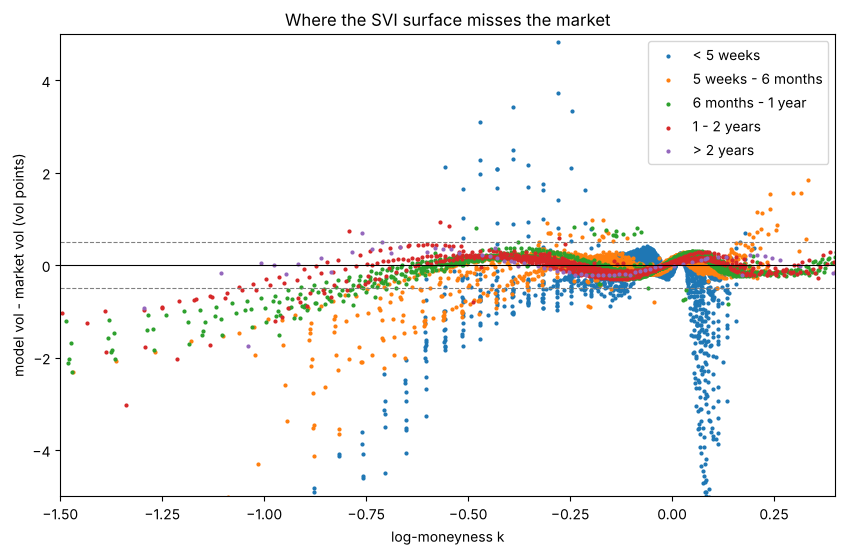

In [8]:
quotes["T_group"] = pd.cut(quotes["T"], [0, 0.1, 0.5, 1, 2.2, 6],
                           labels=["< 5 weeks", "5 weeks - 6 months", "6 months - 1 year", "1 - 2 years", "> 2 years"])
quotes["k_group"] = pd.cut(quotes["k"], [-3.5, -0.6, -0.3, -0.1, 0.05, 0.8])

print("Mean volatility error (vol points)")
print(quotes.pivot_table(index="T_group", columns="k_group", values="err_vol", aggfunc="mean", observed=True).round(2))

plt.figure(figsize=(10, 6))
for group, sub in quotes.groupby("T_group", observed=True):
    plt.scatter(sub["k"], sub["err_vol"], s=4, label=group)
plt.axhline(0, color="black", lw=0.8)
plt.axhline(0.5, color="gray", ls="--", lw=0.8)
plt.axhline(-0.5, color="gray", ls="--", lw=0.8)
plt.xlim(-1.5, 0.4)
plt.ylim(-5, 5)
plt.xlabel("log-moneyness k")
plt.ylabel("model vol - market vol (vol points)")
plt.title("Where the SVI surface misses the market")
plt.legend()
plt.show()

### The hedge zone

The hedges studied in this project have maturities between 6 months and 2 years and strikes between
about 55% and 106% of the forward. We measure the errors in this zone separately, in volatility
points and in percent of the price.

In [9]:
zone = quotes[(quotes["T"] >= 0.5) & (quotes["T"] <= 2.2) & (quotes["k"] >= -0.6) & (quotes["k"] <= 0.06)]
price_err = ((zone["p_mod"] - zone["mid"]) / zone["mid"]).abs() * 100

print("Quotes in the hedge zone:", len(zone))
print("Bias (vol points):", round(zone["err_vol"].mean(), 3))
print("RMSE (vol points):", round(np.sqrt((zone["err_vol"] ** 2).mean()), 3))
print("95th percentile |error| (vol points):", round(zone["err_vol"].abs().quantile(0.95), 3))
print("Max |error| (vol points):", round(zone["err_vol"].abs().max(), 3))
print("Inside bid-ask:", round(zone["inside"].mean(), 3))
print("Median price error (%):", round(price_err.median(), 2))
print("95th percentile price error (%):", round(price_err.quantile(0.95), 2))

Quotes in the hedge zone: 1885
Bias (vol points): 0.014
RMSE (vol points): 0.178
95th percentile |error| (vol points): 0.28
Max |error| (vol points): 0.925
Inside bid-ask: 0.126
Median price error (%): 1.34
95th percentile price error (%): 3.13


**Result.** In the hedge zone (1,885 quotes) the surface is almost unbiased (+0.01 volatility points),
with an RMSE of 0.18 points, and 95% of the errors are below 0.28 points. In price, the median error
is 1.3% and 95% of the errors are below 3.1%. The largest errors are outside this zone: in the deep
put wing ($k < -0.6$) the bias is about $-1.2$ points and the median price error about 12%, and
expiries shorter than 5 weeks have an RMSE of about 0.8 points (see the table above).

### Normalized error

The same errors divided by the bid-ask spread in volatility. Values between $-1$ and $1$ mean that
the model is within one spread of the market.

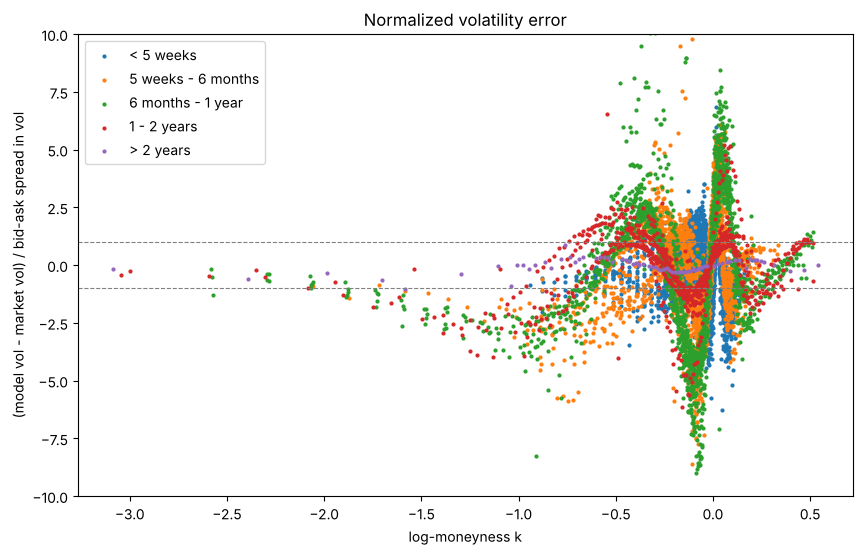

In [10]:
plt.figure(figsize=(10, 6))
for group, sub in quotes.groupby("T_group", observed=True):
    plt.scatter(sub["k"], sub["err_norm"], s=4, label=group)
plt.axhline(1, color="gray", ls="--", lw=0.8)
plt.axhline(-1, color="gray", ls="--", lw=0.8)
plt.ylim(-10, 10)
plt.xlabel("log-moneyness k")
plt.ylabel("(model vol - market vol) / bid-ask spread in vol")
plt.title("Normalized volatility error")
plt.legend()
plt.show()

**Result.** Measured in spreads, the errors look larger: the median absolute normalized error is 1.35
spreads over all quotes and about 2 spreads in the hedge zone. The reason is that the hedge zone is
where the market is most precise, with a median spread of only 0.06 volatility points, so even an
error of 0.1–0.2 points counts as several spreads. For pricing a hedge, the error in price (1–3%)
is the more useful measure.

### Model against bid and ask, by expiry

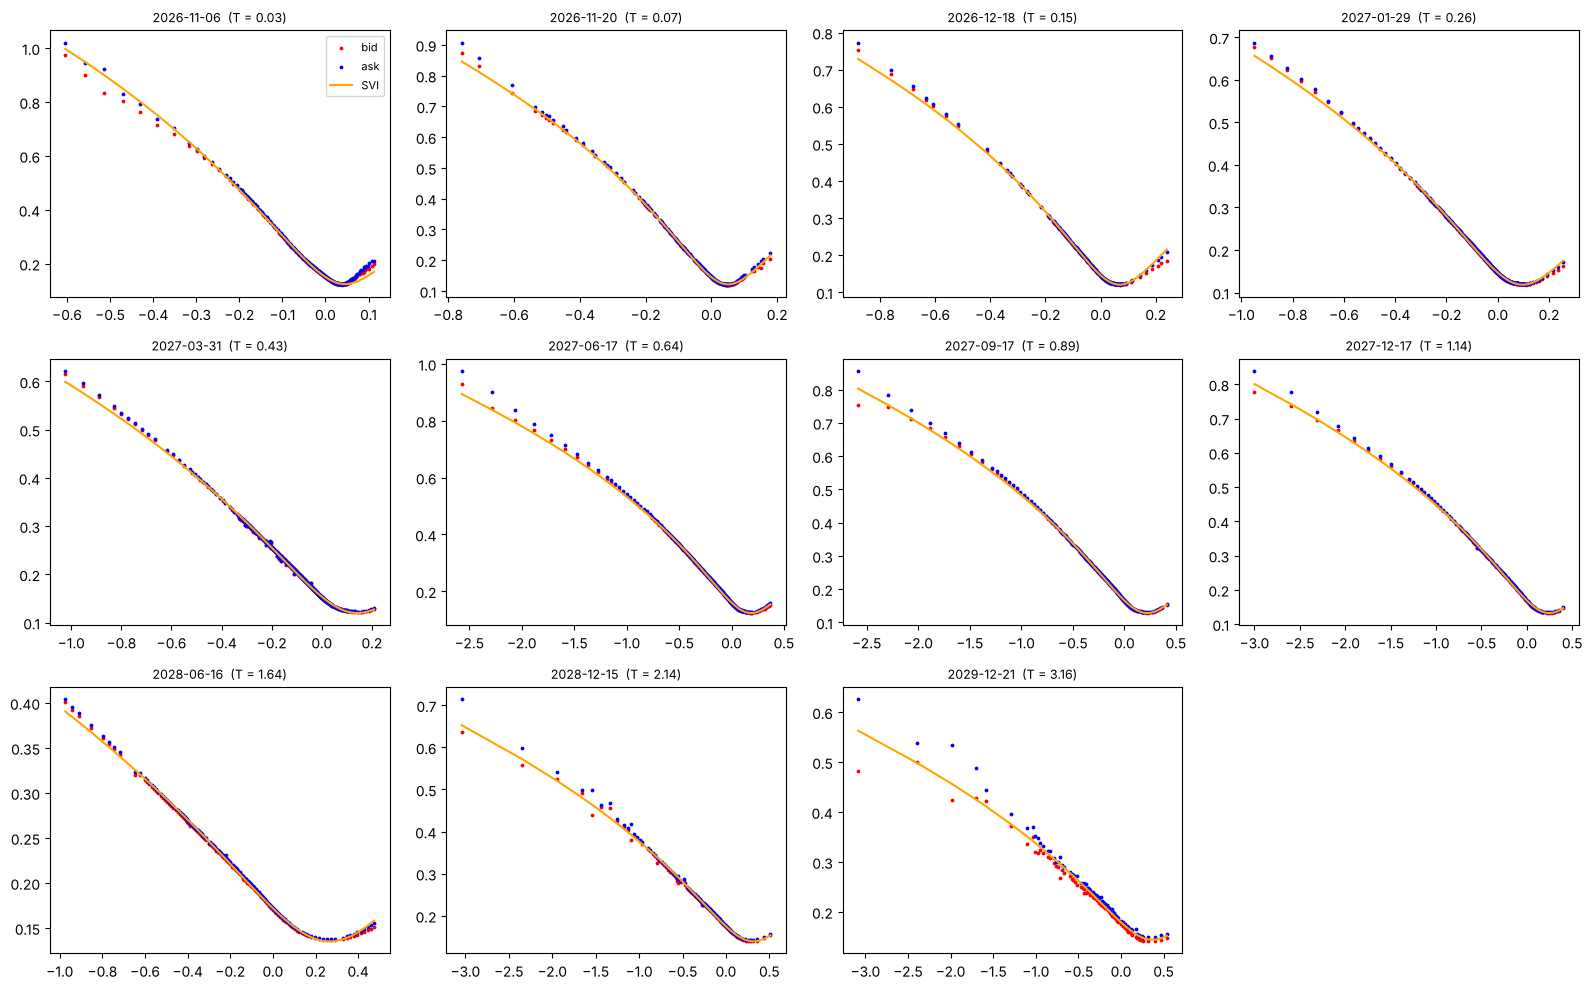

In [11]:
selected = ["2026-11-06", "2026-11-20", "2026-12-18", "2027-01-29", "2027-03-31", "2027-06-17",
            "2027-09-17", "2027-12-17", "2028-06-16", "2028-12-15", "2029-12-21"]
selected = [e for e in selected if e in set(quotes["expiry"])]

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, e in zip(axes.flatten(), selected):
    sub = quotes[quotes["expiry"] == e].sort_values("k")
    ax.scatter(sub["k"], sub["iv_bid"], s=3, color="red", label="bid")
    ax.scatter(sub["k"], sub["iv_ask"], s=3, color="blue", label="ask")
    ax.plot(sub["k"], sub["iv_mod"], color="orange", lw=1.5, label="SVI")
    ax.set_title(f"{e}  (T = {sub['T'].iloc[0]:.2f})", fontsize=9)
for ax in axes.flatten()[len(selected):]:
    ax.axis("off")
axes.flatten()[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5. Conclusions

- Where the hedges are priced (6 months to 2 years, strikes between about 55% and 106% of the
  forward), the surface is close to the market: RMSE 0.18 volatility points and median price error
  1.3%.
- The surface is free of butterfly arbitrage on every slice and free of calendar arbitrage in the
  hedge zone, so it can be interpolated and used for strikes and maturities that are not quoted.
- **Limits.** The fit is weaker in the deep put wing and for expiries shorter than 5 weeks. The
  analysis uses one snapshot of free Yahoo data and Treasury rates (instead of OIS or SOFR rates).
  Model prices are inside the bid-ask only for a minority of quotes, because SPX spreads are tighter
  than the precision of a five-parameter curve.
- **Next steps.** Compare the same hedge prices with a constant volatility and with a simple
  interpolation of market volatilities (QuantLib), and price the hedges of a hypothetical portfolio.

## 6. Saving the surface table

The table `surface` contains everything needed to rebuild the pricer in other notebooks: the SVI
parameters, the forward, the rate and the spot of each calibrated expiry.

In [12]:
out_path = os.path.join(DATA_DIR, SNAPSHOT + "_surface.csv")
surface.to_csv(out_path, index=False)
print("Saved:", out_path, surface.shape)

Saved: data/SPX_2026-10-26_1030_surface.csv (47, 15)
